## install the packages

In [3]:
! pip install streamlit seaborn plotly

  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
Using cached plotly-7.1.0-py3-none-any.whl (9.7 MB)

   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   ---------------------------------------- 0/2 [plotly]
   --------------------------


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## import the libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import streamlit as st

## EDA

In [ ]:
df = sns.load_dataset('titanic') ## pd.read_csv('')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [7]:
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [8]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
df = df[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [10]:
df_new = df.copy()

## Clean data

In [11]:
df_new.isna().sum()

survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64

In [12]:
df_new['age'].fillna(df_new['age'].median(), inplace=True)
df_new['embarked'].fillna(df_new['embarked'].mode()[0], inplace=True)

C:\Users\arezkallah\AppData\Local\Temp\ipykernel_22032\2745395766.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_new['age'].fillna(df_new['age'].median(), inplace=True)
C:\Users\arezkallah\AppData\Local\Temp\ipykernel_22032\2745395766.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves

In [13]:
df_new.isna().sum()

survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

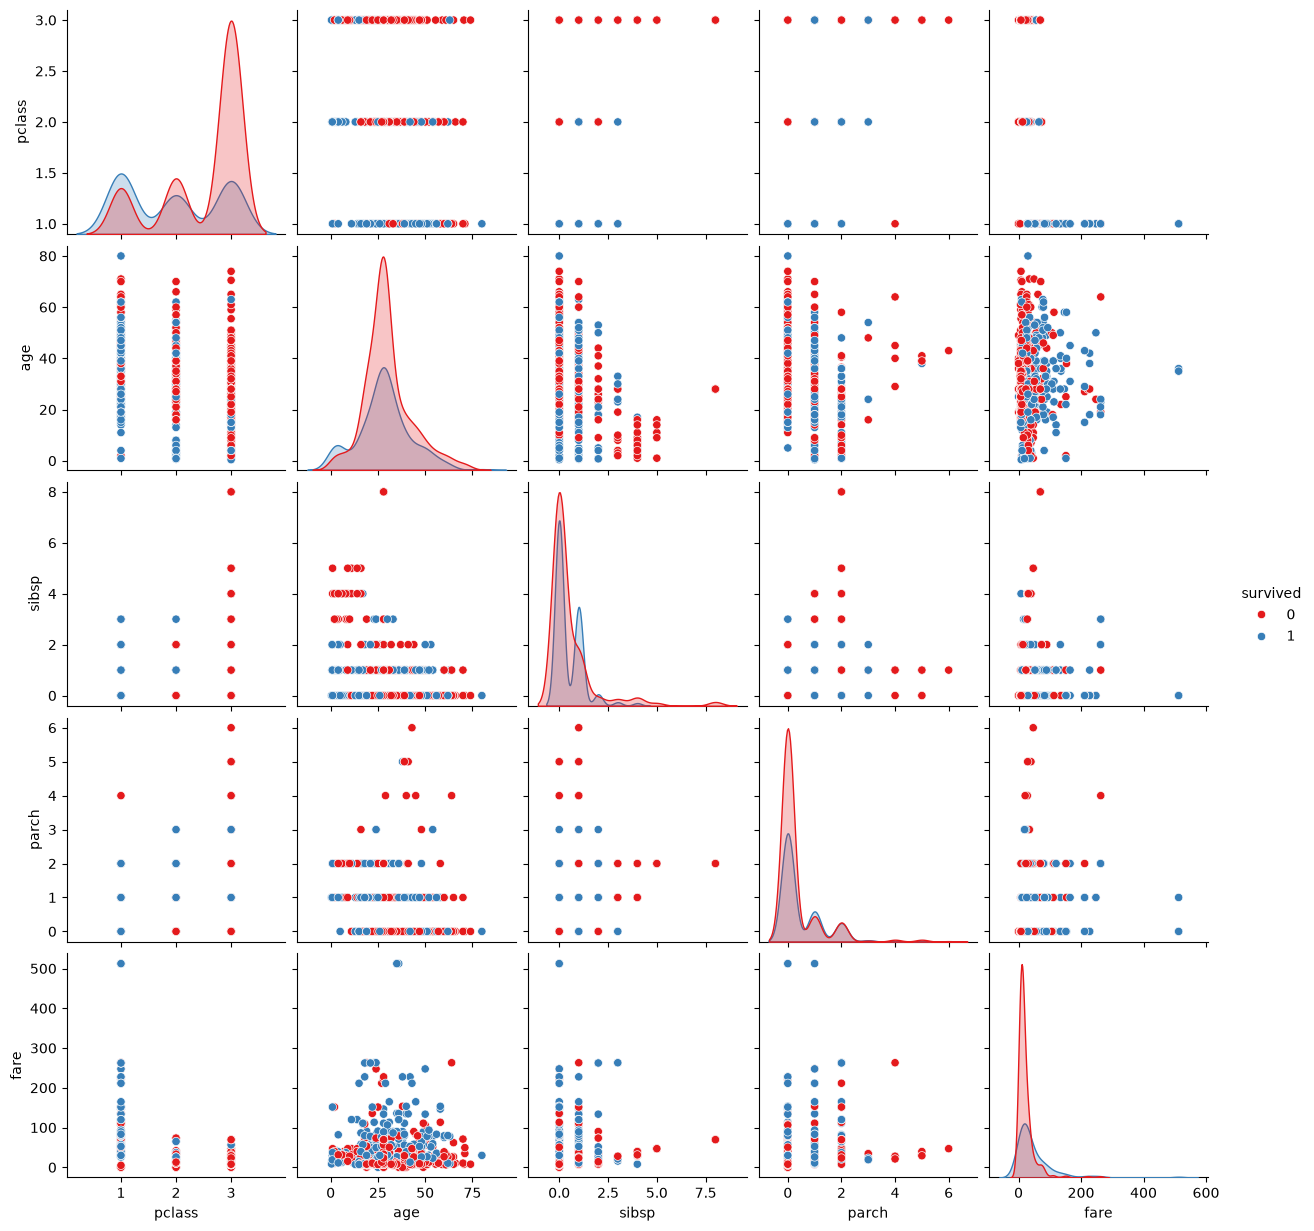

In [14]:
sns.pairplot(df_new, hue='survived', palette='Set1')

<Axes: xlabel='pclass', ylabel='count'>

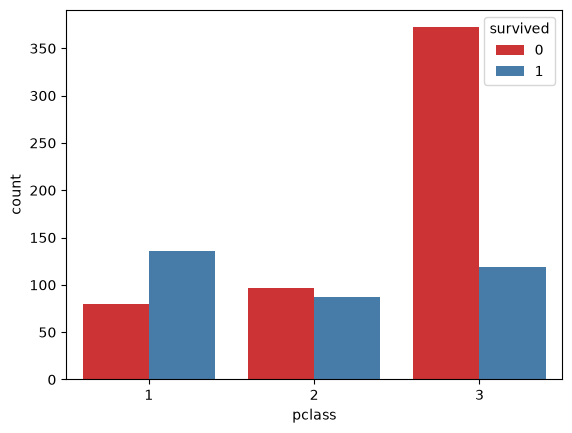

In [15]:
sns.countplot(x='pclass',hue = 'survived', data=df_new, palette='Set1')

<Axes: xlabel='sex', ylabel='count'>

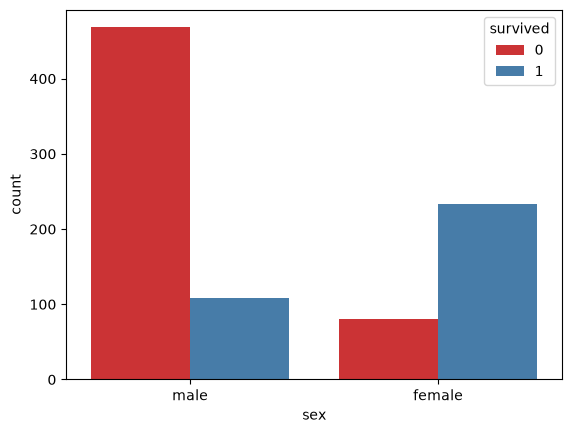

In [16]:
sns.countplot(x='sex',hue = 'survived', data=df_new, palette='Set1')

In [17]:
px.histogram(df_new, x='age', color='survived', marginal='box', nbins=30, title='Age Distribution by Survival')

## split input and output

In [18]:
X = df_new.drop('survived', axis=1)
y = df_new['survived']

In [19]:
X

,pclass,sex,age,sibsp,parch,fare,embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...
886,2,male,27.0,0,0,13.0000,S
887,1,female,19.0,0,0,30.0000,S
888,3,female,28.0,1,2,23.4500,S
889,1,male,26.0,0,0,30.0000,C


In [20]:
X['embarked'].value_counts()

embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [21]:
X = pd.get_dummies(X, columns=['sex', 'embarked'], drop_first=True, dtype=int)
X

,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S
0,3,22.0,1,0,7.2500,1,0,1
1,1,38.0,1,0,71.2833,0,0,0
2,3,26.0,0,0,7.9250,0,0,1
3,1,35.0,1,0,53.1000,0,0,1
4,3,35.0,0,0,8.0500,1,0,1
...,...,...,...,...,...,...,...,...
886,2,27.0,0,0,13.0000,1,0,1
887,1,19.0,0,0,30.0000,0,0,1
888,3,28.0,1,2,23.4500,0,0,1
889,1,26.0,0,0,30.0000,1,0,0


## split data into train and test

In [22]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Apply scaling

In [23]:
sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.transform(x_test)

## Apply the modeling

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
lr = LogisticRegression(random_state=42)
lr.fit(x_train_scaled, y_train)
y_pred = lr.predict(x_test_scaled)
print("classification report training:\n", classification_report(y_train, lr.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       0.82      0.86      0.84       444
           1       0.76      0.69      0.72       268

    accuracy                           0.80       712
   macro avg       0.79      0.78      0.78       712
weighted avg       0.80      0.80      0.80       712

classification report testing:
               precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



In [25]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
y_pred = knn.predict(x_test_scaled)
print("classification report training:\n", classification_report(y_train, knn.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       0.87      0.93      0.90       444
           1       0.87      0.77      0.81       268

    accuracy                           0.87       712
   macro avg       0.87      0.85      0.86       712
weighted avg       0.87      0.87      0.87       712

classification report testing:
               precision    recall  f1-score   support

           0       0.82      0.86      0.84       105
           1       0.78      0.73      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.80      0.80      0.80       179



In [27]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42, max_depth=5)
dt.fit(x_train_scaled, y_train)
y_pred = dt.predict(x_test_scaled)
print("classification report training:\n", classification_report(y_train, dt.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       0.83      0.96      0.89       444
           1       0.91      0.67      0.77       268

    accuracy                           0.85       712
   macro avg       0.87      0.81      0.83       712
weighted avg       0.86      0.85      0.85       712

classification report testing:
               precision    recall  f1-score   support

           0       0.79      0.90      0.84       105
           1       0.83      0.65      0.73        74

    accuracy                           0.80       179
   macro avg       0.81      0.78      0.78       179
weighted avg       0.80      0.80      0.79       179



In [28]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5)
rf.fit(x_train_scaled, y_train)
y_pred = rf.predict(x_test_scaled)
print("classification report training:\n", classification_report(y_train, rf.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       0.83      0.96      0.89       444
           1       0.91      0.68      0.78       268

    accuracy                           0.85       712
   macro avg       0.87      0.82      0.83       712
weighted avg       0.86      0.85      0.85       712

classification report testing:
               precision    recall  f1-score   support

           0       0.81      0.90      0.85       105
           1       0.84      0.69      0.76        74

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.80       179
weighted avg       0.82      0.82      0.81       179



## cross validation

In [30]:
from sklearn.model_selection import KFold, cross_validate
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_validate(rf, x_train_scaled, y_train, cv=kfold, return_train_score=True)
scores

{'fit_time': array([0.38776708, 0.42400336, 0.40884924, 0.22875142, 0.26977921,
        0.14061213, 0.21974754, 0.35773182, 0.16746354, 0.36402178]),
 'score_time': array([0.0734005 , 0.02758169, 0.01040006, 0.01206827, 0.03551126,
        0.00614357, 0.0099225 , 0.00778675, 0.00553918, 0.0082345 ]),
 'test_score': array([0.86111111, 0.80555556, 0.83098592, 0.76056338, 0.78873239,
        0.8028169 , 0.87323944, 0.83098592, 0.84507042, 0.87323944]),
 'train_score': array([0.853125  , 0.85625   , 0.8673947 , 0.87051482, 0.85803432,
        0.85803432, 0.85179407, 0.85647426, 0.85335413, 0.8424337 ])}

## hyper parameter tuning

In [31]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7]
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='accuracy')
grid_search.fit(x_train_scaled, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [3, 5, 7],
                         'n_estimators': [50, 100, 200]},
             scoring='accuracy')

In [32]:
grid_search.best_params_

{'max_depth': 5, 'n_estimators': 100}

In [33]:
rf = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5)
rf.fit(x_train_scaled, y_train)
y_pred = rf.predict(x_test_scaled)
print("classification report training:\n", classification_report(y_train, rf.predict(x_train_scaled)))
print("classification report testing:\n", classification_report(y_test, y_pred))

classification report training:
               precision    recall  f1-score   support

           0       0.83      0.96      0.89       444
           1       0.91      0.68      0.78       268

    accuracy                           0.85       712
   macro avg       0.87      0.82      0.83       712
weighted avg       0.86      0.85      0.85       712

classification report testing:
               precision    recall  f1-score   support

           0       0.81      0.90      0.85       105
           1       0.84      0.69      0.76        74

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.80       179
weighted avg       0.82      0.82      0.81       179



## create the pipeline for deployment

In [34]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,NaN,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


In [35]:
df.isna().sum()

survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64

## split input and output

In [36]:
X = df.drop('survived', axis=1)
y = df['survived']

In [38]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [39]:
numerical_columns = x_train.select_dtypes(include=['int64', 'float64']).columns
numerical_columns

Index(['pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='object')

In [40]:
cat_columns = x_train.select_dtypes(include=['object', 'category']).columns
cat_columns

Index(['sex', 'embarked'], dtype='object')

In [41]:
x_train['embarked'].unique()

array(['S', 'C', 'Q', nan], dtype=object)

In [42]:
x_train['sex'].unique()

array(['male', 'female'], dtype=object)

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler(with_mean=False))
])
numerical_pipeline


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler(with_mean=False))])

In [45]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first'))
])
cat_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(drop='first'))])

In [46]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_columns),
    ('cat', cat_pipeline, cat_columns)
], remainder='passthrough')  # Ensure that any remaining columns are passed through without transformation

In [47]:
preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler',
                                                  StandardScaler(with_mean=False))]),
                                 Index(['pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(drop='first'))]),
                                 Index(['sex', 'embarked'], dtype='object'))])

In [48]:
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5))
])
final_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler(with_mean=False))]),
                                                  Index(['pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first'))]),
                                                  Index(['sex', 'embarked'], dtype='object'))])),
                ('rf', RandomForestClassifier(max_depth=5, random_state=42))])

In [49]:
x_train

,pclass,sex,age,sibsp,parch,fare,embarked
331,1,male,45.5,0,0,28.5000,S
733,2,male,23.0,0,0,13.0000,S
382,3,male,32.0,0,0,7.9250,S
704,3,male,26.0,1,0,7.8542,S
813,3,female,6.0,4,2,31.2750,S
...,...,...,...,...,...,...,...
106,3,female,21.0,0,0,7.6500,S
270,1,male,NaN,0,0,31.0000,S
860,3,male,41.0,2,0,14.1083,S
435,1,female,14.0,1,2,120.0000,S


In [50]:
final_pipeline.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler(with_mean=False))]),
                                                  Index(['pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first'))]),
                                                  Index(['sex', 'embarked'], dtype='object'))])),
                ('rf', RandomForestClassifier(max_depth=5, random_state=42))])

In [51]:
y_pred = final_pipeline.predict(x_test)
y_pred

array([0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       0, 1, 1])

In [52]:
import joblib
joblib.dump(final_pipeline, 'titanic_model.pkl')

['titanic_model.pkl']

In [53]:
classifier = joblib.load('titanic_model.pkl')

In [54]:
classifier.predict(pd.DataFrame({
    'pclass': [3],
    'sex': ['male'],
    'age': [22],
    'sibsp': [1],
    'parch': [0],
    'fare': [7.25],
    'embarked': ['S']
}))


array([0])

In [61]:
%%writefile app.py

import streamlit as st
import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np


classifier = joblib.load('titanic_model.pkl')

def predict_survival(pclass, sex, age, sibsp, parch, fare, embarked):
    input_data = pd.DataFrame({
        'pclass': [pclass],
        'sex': [sex],
        'age': [age],
        'sibsp': [sibsp],
        'parch': [parch],
        'fare': [fare],
        'embarked': [embarked]
    })
    prediction = classifier.predict(input_data)
    label = 'Survived' if prediction[0] == 1 else 'Did not survive'
    return label

def main():
    st.title('Titanic prediction')
    html_temp="""
                <div style="background-color:red">
                <h2 style="color:white;text-align:center;">this our streamlit Deployment App</h2>
                </div>
              """
    st.markdown(html_temp,unsafe_allow_html=True)

    pclass = st.selectbox("Passenger Class (1, 2, 3)", [1, 2, 3])
    sex = st.selectbox("Sex", ['male', 'female'])
    age = st.number_input("Age", min_value=0, max_value=100, value=30)
    sibsp = st.number_input("Number of Siblings/Spouses Aboard", min_value=0, max_value=10, value=0)
    parch = st.number_input("Number of Parents/Children Aboard", min_value=0, max_value=10, value=0)
    fare = st.number_input("Fare", min_value=0.0, max_value=500.0, value=32.2)
    embarked = st.selectbox("Port of Embarkation (C = Cherbourg, Q = Queenstown, S = Southampton)", ['C', 'Q', 'S'])

    if st.button("Predict"):
        result = predict_survival(pclass, sex, age, sibsp, parch, fare, embarked)
        st.success(f"The passenger would have: {result}")    


if __name__ == '__main__':  
    main()

Overwriting app.py
